In [2]:
%pip install pandas opencv-python matplotlib mediapipe scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.3/48.3 MB 25.2 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 22.2 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.2/37.2 MB 22.6 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 23.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 23.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 24.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 24.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 24.8 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.7/55.7 MB 24.7 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19/19 [mediapipe]19 [mediapipe]rn]b-python]
Note: you may need to restart the kernel to use updated packages.


In [10]:
##import libraries needed 
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

print("libraries imported successfully")

libraries imported successfully


In [17]:
#verify the data file can be reached 
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "Datasets"
SQUATS_DIR = DATA_DIR / "Squat Dataset"
REHAB_DIR = DATA_DIR / "Rehab24-6"

print("curr dir:", PROJECT_DIR)
print("Datasets folder exists:", DATA_DIR.exists())
print("squats folder exists:", SQUATS_DIR.exists())
print("rehab dataset exists:", REHAB_DIR.exists())

curr dir: /Users/school/CSCI499/CSCI-499-Capstone-Project
Datasets folder exists: True
squats folder exists: True
rehab dataset exists: True


In [20]:
#check pictures found 
PROJECT_DIR = Path.cwd()
SQUATS_DIR = PROJECT_DIR / "Datasets" / "Squat Dataset" / "Dataset"
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "test"]:
    split_dir = SQUATS_DIR / split
    print(f"\n{split}: exists = {split_dir.exists()}")
    for cls_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        n = sum(1 for f in cls_dir.iterdir() if f.suffix.lower() in IMG_EXT)
        print(f"  {cls_dir.name:<12} {n} images")


train: exists = True
  Bad back     984 images
  Bad heel     852 images
  Good         1001 images

test: exists = True
  Bad Back     338 images
  Bad Heel     321 images
  Good         310 images


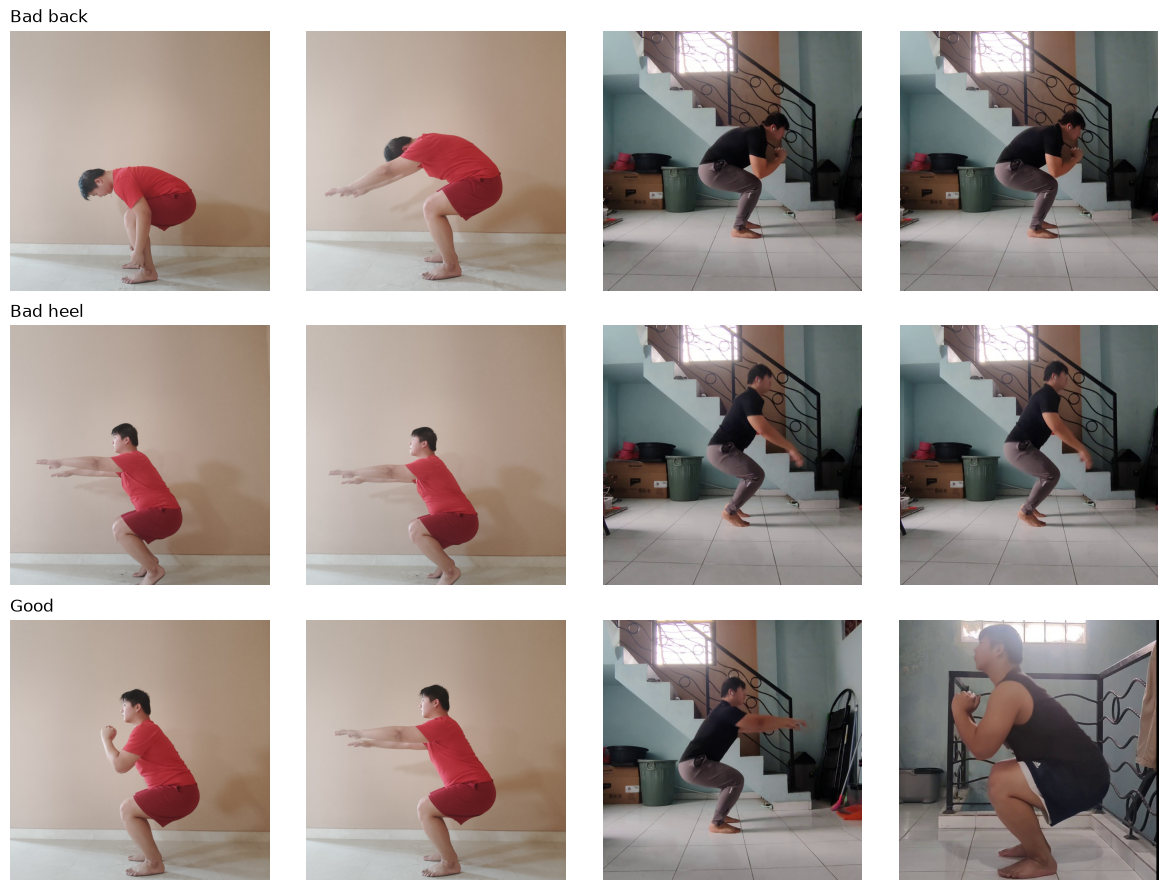

In [23]:
#test some data by checking 
def list_images(folder):
    return sorted(f for f in folder.iterdir() if f.suffix.lower() in IMG_EXT)
##return a sorted list of the image files in the passed in folder

classes = sorted(p.name for p in (SQUATS_DIR / "train").iterdir() if p.is_dir()) ##find all subfolders within 'train' folder
fig, axes = plt.subplots(len(classes), 4, figsize=(12, 3 * len(classes))) ##create grid for displaying images 
for r, cls in enumerate(classes): ##loop through each class (subfolder)
    for c, f in enumerate(list_images(SQUATS_DIR / "train" / cls)[:4]): ##get max 4 photos 
        img = cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)
        axes[r, c].imshow(img); axes[r, c].axis("off")
        if c == 0: axes[r, c].set_title(cls, loc="left") ##title 
plt.tight_layout(); plt.show()